# 06 · Refined signal and combined model: does LPPLS add information?

This notebook presents the output of `lppl combine` (see `docs/combined_model.md`).

**Refined LPPLS signals** (computed from the stored fits, plus a short-scale scan):

| signal | meaning |
|---|---|
| `conf` | long-scale confidence (26 windows, 125–750 days) |
| `conf_short` | the same on 8 short windows (40–180 days) |
| `conf_agree` | √(conf × conf_short): high only when both scales agree |
| `conf_cluster` | qualified fits whose `tc` agree with each other |
| `conf_resid` | qualified fits whose residuals are stationary (Lin et al. 2014) |
| `lagr_pos` | the Lagrange-regularised window holds a qualified fit (Demos & Sornette 2017) |
| `tc_proximity` | how close the median `tc` is |

**Combined model:** nested logistic regressions refitted every year on earlier years only:
*momentum* ⊂ *market* (momentum 21/126/252, volatility ratio, drawdown) ⊂ *market + LPPLS* ⊂
*market + refined LPPLS*. The primary score is the out-of-sample **log-loss**.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from lppl import combined as CM, viz
viz.apply_style()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

LABEL = "full-tuned"                   # report of `make combine` (lppl combine --label full-tuned --short-label full-short)
report_dir = CM.latest_report_dir(label=LABEL) or CM.latest_report_dir()
if report_dir is None:
    raise SystemExit("no report yet: run `make combine` (or `lppl combine ...`) first")
rep = CM.load_report(report_dir)
T, S = rep.tables, rep.summary
print(f"report {report_dir.name}: run {S['run_id'][:8]}, short-scale run {(S.get('short_run_id') or '-')[:8]}, "
      f"out-of-sample years {S['oos_years'][0]}-{S['oos_years'][-1]}")

report full-tuned_0cc0bafd: run 0cc0bafd, short-scale run ac49e3f7, out-of-sample years 1996-2026


## Verdict

The pre-registered tests: does adding the LPPLS confidence improve the out-of-sample log-loss of
the market-only model, and do the refinements improve on it further? (Holm-adjusted, 5 % level)

In [2]:
pd.Series(S["verdict"]).map({True: "yes", False: "no"}).to_frame("significant")

,significant
drawdown_63: market+lppls beats market,no
drawdown_63: market+refined beats market+lppls,no
drawdown_126: market+lppls beats market,no
drawdown_126: market+refined beats market+lppls,no
major_top_126: market+lppls beats market,no
major_top_126: market+refined beats market+lppls,no


## 1 · Out-of-sample scores

Lower log-loss and Brier are better; AP and precision at alarm (the top 2 % of predictions,
threshold set on the training fit) are higher-is-better.

In [3]:
T["metrics"].set_index(["label", "model"])[["n", "base_rate", "log_loss", "brier", "ap", "alarm_rate", "precision_at_alarm"]].round(4)

n  base_rate  log_loss   brier      ap  alarm_rate  precision_at_alarm
label         model                                                                                    
drawdown_63   momentum        7464     0.1436    0.4110  0.1229  0.1695      0.0130              0.2062
              market          7464     0.1436    0.4056  0.1227  0.1940      0.0169              0.1270
              market+lppls    7464     0.1436    0.4062  0.1230  0.1924      0.0176              0.1221
              market+refined  7464     0.1436    0.4072  0.1233  0.1918      0.0182              0.1250
drawdown_126  momentum        7392     0.1544    0.4379  0.1328  0.1580      0.0154              0.2105
              market          7392     0.1544    0.4288  0.1321  0.1987      0.0261              0.2228
              market+lppls    7392     0.1544    0.4297  0.1324  0.1968      0.0249              0.2120
              market+refined  7392     0.1544    0.4317  0.1329  0.1947      0.0198              0.1438
major_top_126 momentum        7236     0.0761    0.2730  0.0719  0.0857      0.0098              0.1127
              market          7236     0.0761    0.2783  0.0751  0.0986      0.0173              0.0480
              market+lppls    7236     0.0761    0.2787  0.0749  0.0969      0.0167              0.0579
              market+refined  7236     0.0761    0.2803  0.0755  0.0952      0.0180              0.0538

## 2 · Improvements with 95 % month-block bootstrap intervals

`log_loss_gain_pct` > 0 means the first model predicts better. `p_holm` is set for the
pre-registered pairs only.

In [4]:
T["increments"][["label", "model", "versus", "log_loss_gain_pct", "ll_ci_low", "ll_ci_high", "p_value", "p_holm",
                  "ap_gain", "ap_ci_low", "ap_ci_high"]].round(4)

,label,model,versus,log_loss_gain_pct,ll_ci_low,ll_ci_high,p_value,p_holm,ap_gain,ap_ci_low,ap_ci_high
0,drawdown_63,market,momentum,1.3281,-0.0021,0.0127,0.0879,NaN,0.0245,0.0062,0.0440
1,drawdown_63,market+lppls,market,-0.1590,-0.0012,-0.0001,0.9920,1.0,-0.0016,-0.0033,-0.0002
2,drawdown_63,market+refined,market+lppls,-0.2420,-0.0023,0.0003,0.9251,1.0,-0.0006,-0.0043,0.0024
3,drawdown_63,market+refined,market,-0.4014,-0.0032,-0.0002,0.9820,NaN,-0.0022,-0.0064,0.0010
4,drawdown_126,market,momentum,2.0774,-0.0005,0.0176,0.0330,NaN,0.0407,0.0240,0.0584
5,drawdown_126,market+lppls,market,-0.2217,-0.0018,-0.0001,0.9880,1.0,-0.0019,-0.0042,0.0000
6,drawdown_126,market+refined,market+lppls,-0.4724,-0.0041,0.0000,0.9740,1.0,-0.0022,-0.0054,0.0010
7,drawdown_126,market+refined,market,-0.6951,-0.0051,-0.0008,0.9980,NaN,-0.0041,-0.0081,-0.0005
8,major_top_126,market,momentum,-1.9392,-0.0129,0.0029,0.9061,NaN,0.0129,0.0027,0.0249
9,major_top_126,market+lppls,market,-0.1506,-0.0020,0.0011,0.6973,1.0,-0.0017,-0.0050,0.0013


## 3 · Year by year

The gain over the market-only model in each out-of-sample year. A real signal helps in most
years, not only in one lucky episode.

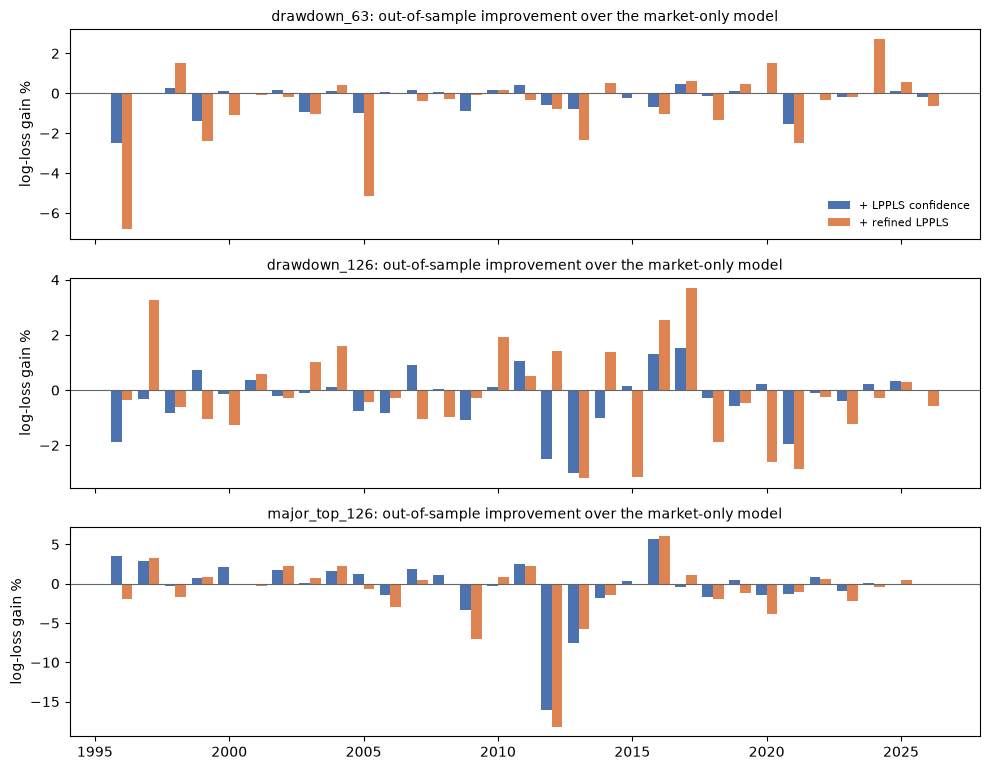

,label,year,n,events,ll_momentum,ap_momentum,ll_market,ap_market,ll_market+lppls,ap_market+lppls,ll_market+refined,ap_market+refined
0,drawdown_63,1996,130,28,0.554,0.365,0.544,0.273,0.557,0.215,0.581,0.202
1,drawdown_63,1997,125,37,0.672,0.436,0.708,0.314,0.708,0.274,0.708,0.298
2,drawdown_63,1998,141,29,0.485,0.438,0.483,0.402,0.482,0.423,0.476,0.435
3,drawdown_63,1999,150,6,0.239,0.112,0.232,0.328,0.235,0.129,0.237,0.170
4,drawdown_63,2000,173,77,0.960,0.489,0.929,0.585,0.928,0.600,0.939,0.578
...,...,...,...,...,...,...,...,...,...,...,...,...
87,major_top_126,2021,300,64,0.591,0.218,0.632,0.176,0.640,0.170,0.638,0.180
88,major_top_126,2022,300,0,0.039,NaN,0.031,NaN,0.031,NaN,0.031,NaN
89,major_top_126,2023,300,0,0.103,NaN,0.082,NaN,0.083,NaN,0.084,NaN
90,major_top_126,2024,300,48,0.469,0.140,0.510,0.108,0.510,0.108,0.513,0.109


In [5]:
display(Image(str(report_dir / "per_year_gain.png")))
T["per_year"].round(3)

## 4 · Calibration

Predicted probability against the realised event rate (deciles of the out-of-sample predictions).
Points on the diagonal are well calibrated.

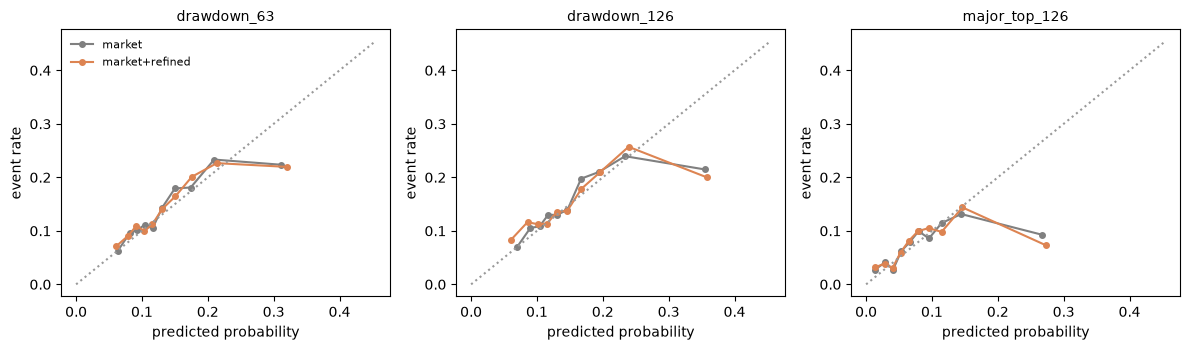

In [6]:
display(Image(str(report_dir / "calibration.png")))

## 5 · Each LPPLS signal on its own

AP, lift over the base rate and the circular time-shift placebo p-value (1,000 shifts). These
are descriptive: no model is fitted.

In [7]:
T["standalone"].pivot_table(index="signal", columns="label", values=["lift", "p_placebo"]).round(3)

lift                              p_placebo                          
label        drawdown_126 drawdown_63 major_top_126 drawdown_126 drawdown_63 major_top_126
signal                                                                                    
conf                1.008       1.022         1.211        0.361       0.229         0.005
conf_agree          0.986       1.019         1.021        0.914       0.116         0.169
conf_cluster        1.012       1.004         1.197        0.331       0.401         0.003
conf_resid          1.006       1.019         1.212        0.373       0.254         0.003
conf_short          0.990       1.022         1.048        0.835       0.106         0.060
lagr_pos            1.004       1.017         1.020        0.298       0.044         0.103
momentum            0.972       1.028         1.575        0.741       0.415         0.003
tc_proximity        0.986       1.008         1.242        0.704       0.464         0.001

## 6 · Coefficients of the largest model (full sample, standardised)

Descriptive only. The coefficients are partial effects given all the other columns, and
correlated signals share their effect.

In [8]:
T["coefficients"].pivot_table(index="term", columns="label", values="coef_per_sd", sort=False).round(3)

label,drawdown_63,drawdown_126,major_top_126
term,,,
intercept,-1.926,-1.812,-2.750
mom_21,0.032,-0.008,0.024
mom_126,0.755,0.452,-0.346
mom_252,0.354,0.355,0.370
vol_ratio,0.314,0.374,0.309
drawdown_252,-0.481,-0.327,0.679
conf,0.739,0.011,-0.379
conf_short,0.111,0.127,0.079
conf_agree,-0.045,-0.201,-0.163


## 7 · Inside strong rallies

The event rate in the top momentum quintile, split by whether each LPPLS signal fires.

In [9]:
F = T["features"]
lab = [c for c in ("drawdown_63", "drawdown_126", "major_top_126") if c in F]
F = F.dropna(subset=["mom_126"])
hot = F[F["mom_126"] >= F["mom_126"].quantile(0.8)]
rows = []
for sig, thr in [("conf", 0.3), ("conf_short", 0.3), ("conf_agree", 0.3), ("conf_cluster", 0.2),
                 ("conf_resid", 0.2), ("lagr_pos", 0.5)]:
    if hot[sig].notna().any():
        on = hot[sig].fillna(0) >= thr
        rows.append({"signal": f"{sig} >= {thr}", "dates on": int(on.sum()),
                     **{f"{l}: on": hot.loc[on, l].mean() for l in lab},
                     **{f"{l}: off": hot.loc[~on, l].mean() for l in lab}})
pd.DataFrame(rows).set_index("signal").round(3)

,dates on,drawdown_63: on,drawdown_126: on,major_top_126: on,drawdown_63: off,drawdown_126: off,major_top_126: off
signal,,,,,,,
conf >= 0.3,189,0.138,0.169,0.137,0.159,0.152,0.122
conf_short >= 0.3,64,0.203,0.125,0.127,0.154,0.155,0.124
conf_agree >= 0.3,46,0.196,0.022,0.087,0.155,0.158,0.125
conf_cluster >= 0.2,180,0.123,0.173,0.172,0.160,0.152,0.118
conf_resid >= 0.2,299,0.154,0.171,0.144,0.157,0.150,0.119
lagr_pos >= 0.5,179,0.169,0.164,0.148,0.155,0.153,0.121
